# 08 Â· Priorities and situation report

**Mission.** Make an auditable exercise priority list and concise handover.

![Illustrated OSIRIS VEOC mission board](assets/veoc-splash.svg)

> **Exercise only.** All sectors, calls, flood depths, beds, and travel times below are invented. Run each notebook independently with the **Python (Pyodide)** kernel in JupyterLite. First startup downloads the browser runtime. The linked OSIRIS console is a separate application.

[Book home](intro.md) Â· [2D operations map](https://jltobias.github.io/JupyterLite-Osiris/scenes/operations-2d.html) Â· [3D scene](https://jltobias.github.io/JupyterLite-Osiris/scenes/operations-3d.html) Â· [OSIRIS](https://osirisai.live/)

In [1]:
import math, json, statistics
from datetime import datetime, timezone
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, HTML, Markdown
plt.rcParams.update({"figure.figsize": (9, 4), "axes.spines.top": False, "axes.spines.right": False})
SECTORS = [
 {"name":"Harbor", "lat":29.93,"lon":-90.07,"population":18000,"calls":34,"flood_m":0.9,"open_beds":12,"road_min":28,"reporting":0.84},
 {"name":"Eastbank","lat":29.96,"lon":-90.00,"population":24000,"calls":22,"flood_m":0.4,"open_beds":24,"road_min":19,"reporting":0.91},
 {"name":"Canal",   "lat":29.98,"lon":-90.10,"population":12000,"calls":31,"flood_m":1.4,"open_beds":4, "road_min":42,"reporting":0.68},
 {"name":"North",   "lat":30.05,"lon":-90.07,"population":30000,"calls":18,"flood_m":0.1,"open_beds":38,"road_min":14,"reporting":0.96},
 {"name":"Bayou",   "lat":29.89,"lon":-90.12,"population":9000, "calls":25,"flood_m":1.1,"open_beds":7, "road_min":51,"reporting":0.72},
 {"name":"Airport", "lat":30.00,"lon":-90.25,"population":16000,"calls":11,"flood_m":0.2,"open_beds":18,"road_min":23,"reporting":0.89},
]
for sector in SECTORS:
    sector["rate_10k"] = sector["calls"] / sector["population"] * 10000
print("EXERCISE DATA â€” fictional sectors, observations and facilities; no real incident implied")

EXERCISE DATA â€” fictional sectors, observations and facilities; no real incident implied


## Explicit weights
This score demonstrates how assumptions change the ranking. It does **not** automate emergency decisions. Terms use normalized synthetic call rate, flood depth, road time, and a reporting gap. Discuss weights and missing data with the incident team.

In [2]:
weights={'calls':.35,'flood':.30,'access':.20,'gap':.15}
for s in SECTORS:
 s['priority']=weights['calls']*min(s['rate_10k']/30,1)+weights['flood']*min(s['flood_m']/1.5,1)+weights['access']*min(s['road_min']/60,1)+weights['gap']*(1-s['reporting'])
ranking=sorted(SECTORS,key=lambda x:x['priority'],reverse=True)
for rank,s in enumerate(ranking,1):print(f"{rank}. {s['name']:8} {s['priority']:.3f} | reporting {s['reporting']:.0%}")

1. Canal    0.769 | reporting 68%
2. Bayou    0.756 | reporting 72%
3. Harbor   0.518 | reporting 84%
4. Eastbank 0.264 | reporting 91%
5. Airport  0.213 | reporting 89%
6. North    0.143 | reporting 96%


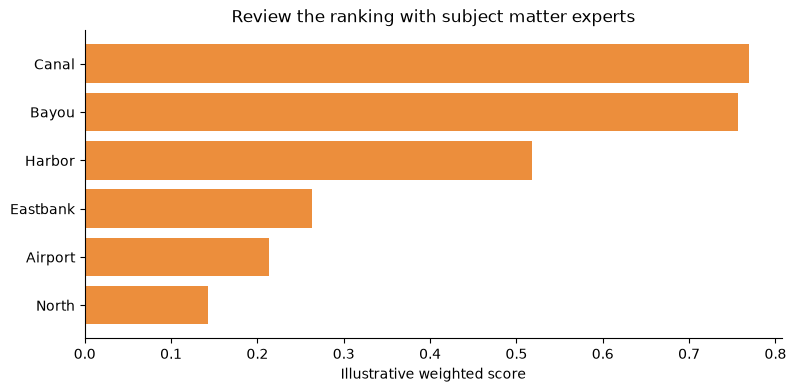

In [3]:
fig,ax=plt.subplots();ax.barh([s['name'] for s in ranking],[s['priority'] for s in ranking],color='#ec8e3c');ax.invert_yaxis();ax.set(xlabel='Illustrative weighted score',title='Review the ranking with subject matter experts');plt.show()

In [4]:
sitrep=f"""# EXERCISE SITREP Â· T+4
## Situation
Fictional heavy rain and assistance calls across six sectors. No real incident is represented.
## Verified / modeled / unknown
Verified: none in this exercise dataset. Modeled: flood depths and road travel times. Unknown: actual closures, shelter demand, medical acuity.
## Priority for verification
{', '.join(s['name'] for s in ranking[:2])} (illustrative score; review with field teams).
## Next update
Obtain timestamped field reports and publish an updated map with source links.
"""
display(Markdown(sitrep))

# EXERCISE SITREP Â· T+4
## Situation
Fictional heavy rain and assistance calls across six sectors. No real incident is represented.
## Verified / modeled / unknown
Verified: none in this exercise dataset. Modeled: flood depths and road travel times. Unknown: actual closures, shelter demand, medical acuity.
## Priority for verification
Canal, Bayou (illustrative score; review with field teams).
## Next update
Obtain timestamped field reports and publish an updated map with source links.


## Field exercise and review
Double the reporting-gap weight and renormalize the weights. Does the first priority change? Add a dated decision log entry describing why the team accepted or rejected the score.

## Source desk
- [OSIRIS source and MIT license](https://github.com/simplifaisoul/osiris) Â· [OSIRIS live console](https://osirisai.live/)
- [USGS Earthquake API](https://earthquake.usgs.gov/fdsnws/event/1/) Â· [NASA EONET](https://eonet.gsfc.nasa.gov/docs/v3) Â· [NASA FIRMS](https://firms.modaps.eosdis.nasa.gov/)
- [NOAA National Hurricane Center](https://www.nhc.noaa.gov/) Â· [GDACS](https://www.gdacs.org/) Â· [OpenSky Network](https://opensky-network.org/)

**Use rule:** A source link provides context, not independent confirmation of this fictional exercise. Check timestamps, geography, provider terms, and incident command procedures before any real decision.